In [18]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.impute import SimpleImputer

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import LinearSVC

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import GradientBoostingClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [19]:
#loading data sets
data=pd.read_csv("/content/bank-additional-full.csv")

In [13]:
data

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41183,73,retired,married,professional.course,no,yes,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes
41184,46,blue-collar,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41185,56,retired,married,university.degree,no,yes,no,cellular,nov,fri,...,2,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,no
41186,44,technician,married,professional.course,no,no,no,cellular,nov,fri,...,1,999,0,nonexistent,-1.1,94.767,-50.8,1.028,4963.6,yes


In [14]:
data.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [20]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [21]:
data.columns

Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

In [22]:
#Check missing values
data.isnull().sum()

,0
age,0
job,0
marital,0
education,0
default,0
housing,0
loan,0
contact,0
month,0
day_of_week,0


no missing values

In [24]:
#Check duplicate records
data.duplicated().sum()

np.int64(12)

In [26]:
data.drop_duplicates(inplace=True)

duplicated 12 records are removed

In [27]:
data.duplicated().sum()

np.int64(0)

In [29]:
#Numerical and Categorical Features
num_col = data.select_dtypes(include=np.number).columns

print(num_col)
cat_col = data.select_dtypes(include="object").columns

print(cat_col)

Index(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'],
      dtype='object')
Index(['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact',
       'month', 'day_of_week', 'poutcome', 'y'],
      dtype='object')


In [31]:
#target variable analyzation
data['y'].value_counts()

,count
y,
no,36537
yes,4639


In [32]:
data['y'].value_counts(normalize=True) * 100

,proportion
y,
no,88.733728
yes,11.266272


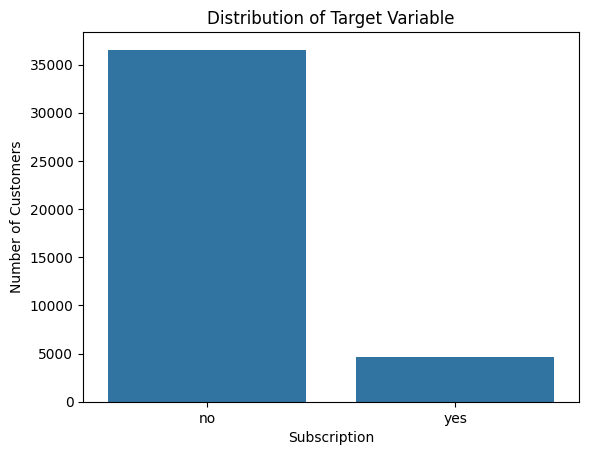

In [34]:
#visualizing
sns.countplot(x='y', data=data)

plt.title("Distribution of Target Variable")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")

plt.show()

**Data Preprocessing**

In [35]:
#Handling missing or unknown values.
OneHotEncoder(handle_unknown='ignore')

OneHotEncoder(handle_unknown='ignore')

In [36]:
'''Separate Input and Output
X = Independent variables (input features)

y = Dependent variable (target/output)'''

X = data.drop('y', axis=1)

y = data['y']

In [37]:
#target variable into numerical values.
y = y.map({'no': 0, 'yes': 1})

In [38]:
X = X.drop('duration',axis=1)

ENCODING AND SCALING

In [39]:
num_col = X.select_dtypes(include=np.number).columns

cat_col = X.select_dtypes(include='object').columns

In [41]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

In [42]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [43]:
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_col),
    ('cat', cat_pipeline, cat_col)
])

Split the Dataset into Training and Testing **Sets**

In [46]:
X_train,X_test,y_train,y_test= train_test_split(

    X,y,
   test_size=0.2,
   random_state=42,
   stratify=y
)

In [47]:
print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(32940, 19)
(8236, 19)
(32940,)
(8236,)


** Application of classisfiaction model**

In [49]:
#Create a function to train and evaluate models
results = []

def evaluate_model(name, model):

    pipe = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])

    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(y_test, y_pred, zero_division=0)

    recall = recall_score(y_test, y_pred, zero_division=0)

    f1 = f1_score(y_test, y_pred, zero_division=0)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

    print(name)
    print(classification_report(y_test, y_pred))

    return pipe

In [50]:
#.1 Logistic Regression
lr = evaluate_model(
    "Logistic Regression",
    LogisticRegression(max_iter=2000, class_weight='balanced')
)

Logistic Regression
              precision    recall  f1-score   support

           0       0.95      0.85      0.90      7308
           1       0.36      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.65      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236



In [51]:
#K-Nearest Neighbors (KNN)
knn = evaluate_model(
    "KNN",
    KNeighborsClassifier(n_neighbors=5)
)

KNN
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      7308
           1       0.57      0.31      0.40       928

    accuracy                           0.90      8236
   macro avg       0.74      0.64      0.67      8236
weighted avg       0.88      0.90      0.88      8236



In [52]:
#svm
svm = evaluate_model(
    "SVM",
    LinearSVC(class_weight='balanced', max_iter=5000, random_state=42)
)

SVM
              precision    recall  f1-score   support

           0       0.95      0.85      0.90      7308
           1       0.36      0.65      0.46       928

    accuracy                           0.83      8236
   macro avg       0.66      0.75      0.68      8236
weighted avg       0.88      0.83      0.85      8236



In [53]:
#decison tree classifier
dt = evaluate_model(
    "Decision Tree",
    DecisionTreeClassifier(
        max_depth=10,
        class_weight='balanced',
        random_state=42
    )
)

Decision Tree
              precision    recall  f1-score   support

           0       0.95      0.88      0.91      7308
           1       0.39      0.60      0.47       928

    accuracy                           0.85      8236
   macro avg       0.67      0.74      0.69      8236
weighted avg       0.88      0.85      0.86      8236



**Ensemble Learning Methods**

In [54]:
#Random forest classisfier
rf = evaluate_model(
    "Random Forest",
    RandomForestClassifier(
        n_estimators=100,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
)

Random Forest
              precision    recall  f1-score   support

           0       0.91      0.97      0.94      7308
           1       0.55      0.27      0.36       928

    accuracy                           0.89      8236
   macro avg       0.73      0.62      0.65      8236
weighted avg       0.87      0.89      0.88      8236



In [55]:
#bagging classifier
bag = evaluate_model(
    "Bagging Classifier",
    BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=10),
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    )
)

Bagging Classifier
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      7308
           1       0.64      0.27      0.38       928

    accuracy                           0.90      8236
   macro avg       0.78      0.62      0.66      8236
weighted avg       0.88      0.90      0.88      8236



In [56]:
#ADAboost classifier
ada = evaluate_model(
    "AdaBoost",
    AdaBoostClassifier(
        n_estimators=50,
        random_state=42
    )
)


AdaBoost
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      7308
           1       0.69      0.20      0.31       928

    accuracy                           0.90      8236
   macro avg       0.80      0.59      0.63      8236
weighted avg       0.88      0.90      0.87      8236



In [57]:
#gradient boost classifier\
gb = evaluate_model(
    "Gradient Boosting",
    GradientBoostingClassifier(
        n_estimators=100,
         learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
)

Gradient Boosting
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      7308
           1       0.65      0.23      0.34       928

    accuracy                           0.90      8236
   macro avg       0.78      0.61      0.64      8236
weighted avg       0.88      0.90      0.88      8236



**MODEL EVALUATION **

In [59]:
'''
Accuracy = Correct Predictions / Total Predictions
Precision = TP / (TP + FP)
Recall = TP / (TP + FN)
F1 Score = 2 * (Precision * Recall) / (Precision + Recall)
'''

'\nAccuracy = Correct Predictions / Total Predictions\nPrecision = TP / (TP + FP)\nRecall = TP / (TP + FN)\nF1 Score = 2 * (Precision * Recall) / (Precision + Recall)\n'

In [60]:
#COMPARING all models
results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.830257,0.359113,0.645474,0.461479
1,KNN,0.895459,0.566075,0.309267,0.400000
2,SVM,0.831107,0.360961,0.647629,0.463556
3,Decision Tree,0.847256,0.385892,0.601293,0.470093
4,Random Forest,0.892545,0.546436,0.272629,0.363767
5,Bagging Classifier,0.900437,0.638462,0.268319,0.377845
6,AdaBoost,0.899709,0.694656,0.196121,0.305882
7,Gradient Boosting,0.899466,0.650602,0.232759,0.342857


In [61]:
results_df.sort_values(
    by='F1 Score',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
3,Decision Tree,0.847256,0.385892,0.601293,0.470093
2,SVM,0.831107,0.360961,0.647629,0.463556
0,Logistic Regression,0.830257,0.359113,0.645474,0.461479
1,KNN,0.895459,0.566075,0.309267,0.400000
5,Bagging Classifier,0.900437,0.638462,0.268319,0.377845
4,Random Forest,0.892545,0.546436,0.272629,0.363767
7,Gradient Boosting,0.899466,0.650602,0.232759,0.342857
6,AdaBoost,0.899709,0.694656,0.196121,0.305882


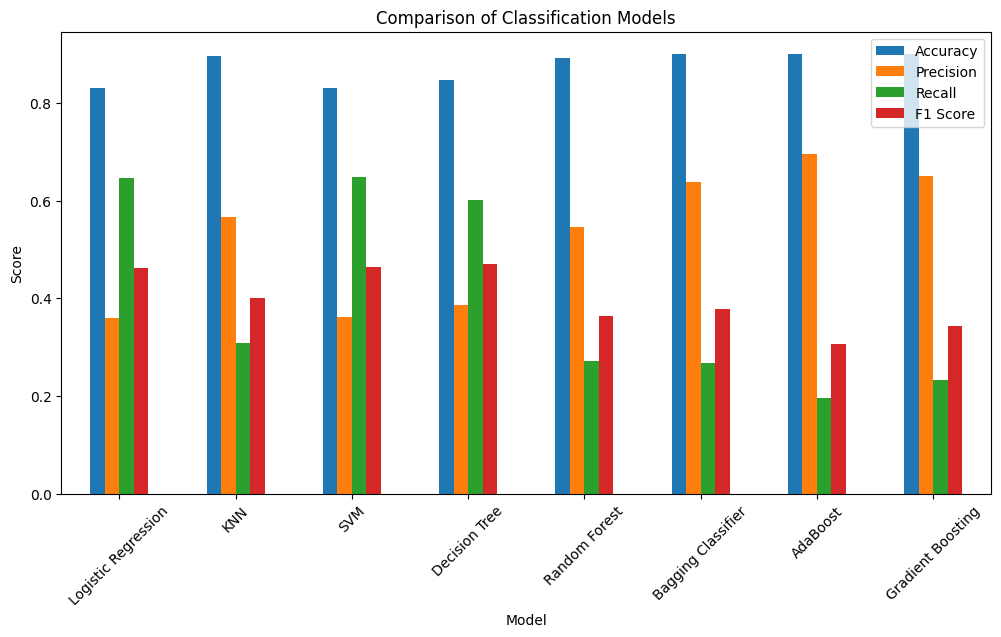

In [62]:
#visualizing
results_df.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', figsize=(12, 6))

plt.title("Comparison of Classification Models")

plt.ylabel("Score")

plt.xticks(rotation=45)

plt.legend()

plt.show()

the Best-Performing Model

In [63]:
best_model = results_df.sort_values(
    by='F1 Score',
    ascending=False
).iloc[0]

print("Best Performing Model:", best_model['Model'])

print("Accuracy:", best_model['Accuracy'])

print("Precision:", best_model['Precision'])

print("Recall:", best_model['Recall'])

print("F1 Score:", best_model['F1 Score'])

Best Performing Model: Decision Tree
Accuracy: 0.8472559494900437
Precision: 0.38589211618257263
Recall: 0.6012931034482759
F1 Score: 0.4700926705981466


Confusion Matrix

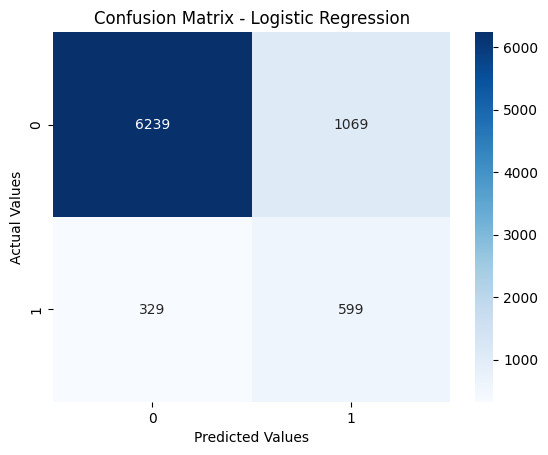

In [64]:
y_pred = lr.predict(X_test)

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.title("Confusion Matrix - Logistic Regression")

plt.xlabel("Predicted Values")

plt.ylabel("Actual Values")

plt.show()

Feature Importance and Interpretation

In [65]:
rf_model = rf.named_steps['model']

feature_names = rf.named_steps[
    'preprocessing'
].get_feature_names_out()

importance = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
0,num__age,0.135055
7,num__euribor3m,0.127278
1,num__campaign,0.075351
8,num__nr.employed,0.059780
4,num__emp.var.rate,0.046923
6,num__cons.conf.idx,0.028278
5,num__cons.price.idx,0.020803
36,cat__housing_no,0.018991
38,cat__housing_yes,0.018674
2,num__pdays,0.018385


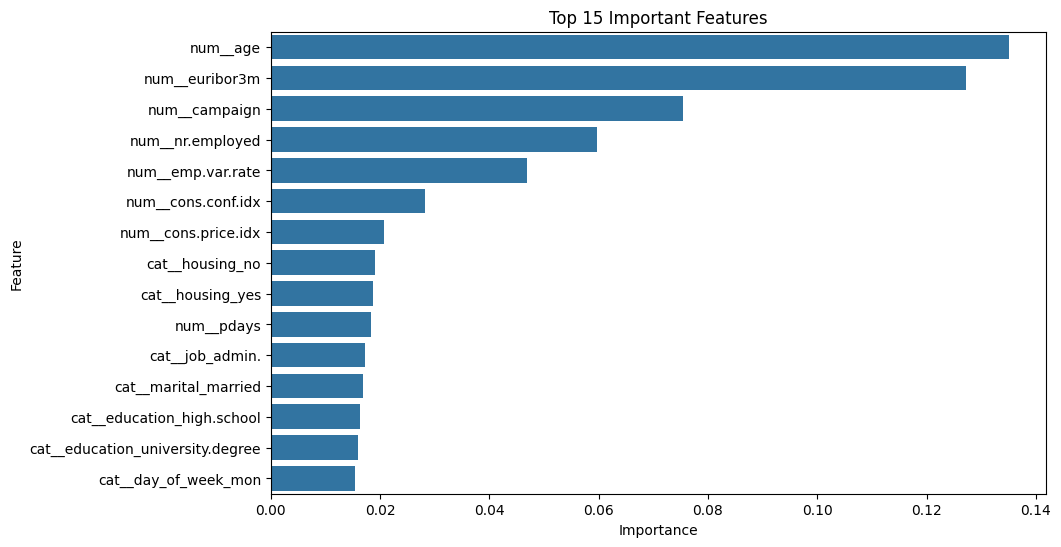

In [66]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")

plt.show()

Business Insights


1.The bank can use the classification model to identify customers who are more likely to subscribe.



2.The bank can focus its marketing campaigns on customer groups that show a higher probability of subscription.


3.Instead of contacting every customer, the bank can prioritize potential customers and reduce unnecessary marketing calls.
